# Análisis Exploratorio y Baselines

## Objetivo del notebook

Este notebook cubre la fase inicial del proyecto:

1. **Contacto con los datos:** estructura, volumen, distribución del objetivo y riesgos observados.
2. **Análisis exploratorio** de features numéricas y correlaciones.
3. **Baselines** (media por sexo y Ridge) con evaluación por corredor.
4. **Prueba preliminar** de la MLP para verificar viabilidad del pipeline.

> **Nota:** Este notebook lee directamente `data/processed/df_long.parquet`, generado por `src/data_processing.py`. Si no existe, ejecuta primero `python src/data_processing.py`.

## Contenido

1. [Configuración y carga](#1)
2. [Evidencia de contacto con los datos](#2)
   - 2.1 Número de ejemplos y corredores
   - 2.2 Distribución del objetivo
   - 2.3 Distribución de variables de entrada
   - 2.4 Datos faltantes y valores atípicos
   - 2.5 Riesgos observados
3. [Baselines](#3)
4. [Familia de modelos: MLP](#4)
5. [Primer experimento: Ridge vs. MLP](#5)
6. [Conclusiones preliminares](#6)

<a name="1"></a>
# 1. Configuración y carga

In [1]:
# @title Imports y configuración
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

# Seed global para reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
pd.set_option("display.max_columns", None)

print(f"torch:      {torch.__version__}")
print(f"pandas:     {pd.__version__}")
print(f"Dispositivo: {DEVICE}")

torch:      2.15.0
pandas:     3.1.0
Dispositivo: cpu


In [2]:
# @title Carga de datos procesados

def find_repo_root(start: Path = Path.cwd()) -> Path:
    """Sube por el árbol de directorios hasta encontrar data/processed/df_long.parquet."""
    for p in [start, *start.parents]:
        if (p / "data" / "processed" / "df_long.parquet").exists():
            return p
    raise FileNotFoundError(
        "No se encontró data/processed/df_long.parquet. "
        "Ejecuta primero: python src/data_processing.py"
    )

ROOT = find_repo_root()
PARQUET_PATH = ROOT / "data" / "processed" / "df_long.parquet"

df_long = pd.read_parquet(PARQUET_PATH)

print(f"Cargado: {PARQUET_PATH.relative_to(ROOT)}")
print(f"Shape:   {df_long.shape[0]} filas × {df_long.shape[1]} columnas")
df_long.head()

Cargado: data/processed/df_long.parquet
Shape:   5153 filas × 18 columnas


,id,age,bmi,female,endurancecat,endurancespeed,typical,sprint,tempo,max,injury,footwear,tiempo_ajustado_s,forma_fisica,dificultad,distancia,distancia_km,velocity_kmh
0,2,41.0,23.905970,0,1,2,23.0,1,1,28.0,1,2,1210.000000,2.0,3.0,5K,5.0,14.876033
1,3,25.0,21.640728,0,2,3,50.0,1,1,70.0,1,2,994.000061,2.0,3.0,5K,5.0,18.108651
2,4,35.0,23.592323,0,2,5,50.0,1,1,60.0,2,2,1075.000000,1.0,3.0,5K,5.0,16.744186
3,5,34.0,22.706404,0,2,3,8.0,0,0,15.0,1,2,1186.000000,1.0,3.0,5K,5.0,15.177066
4,6,45.0,42.087543,1,1,1,10.0,0,1,15.0,2,2,3240.000000,2.0,3.0,5K,5.0,5.555556


<a name="2"></a>
# 2. Evidencia de contacto con los datos

Esta sección presenta evidencia directa obtenida del código: volumen, distribución del objetivo, features y riesgos observados.

## 2.1. Número de ejemplos y corredores

Carreras (ejemplos): 5153
Corredores únicos:   2164
Carreras/corredor:   media=2.38, min=2, max=3

--- Carreras por distancia ---
distancia
Media maratón    1444
5K               1289
Maratón           929
10K               883
10mi              313
5mi               295
Name: count, dtype: int64


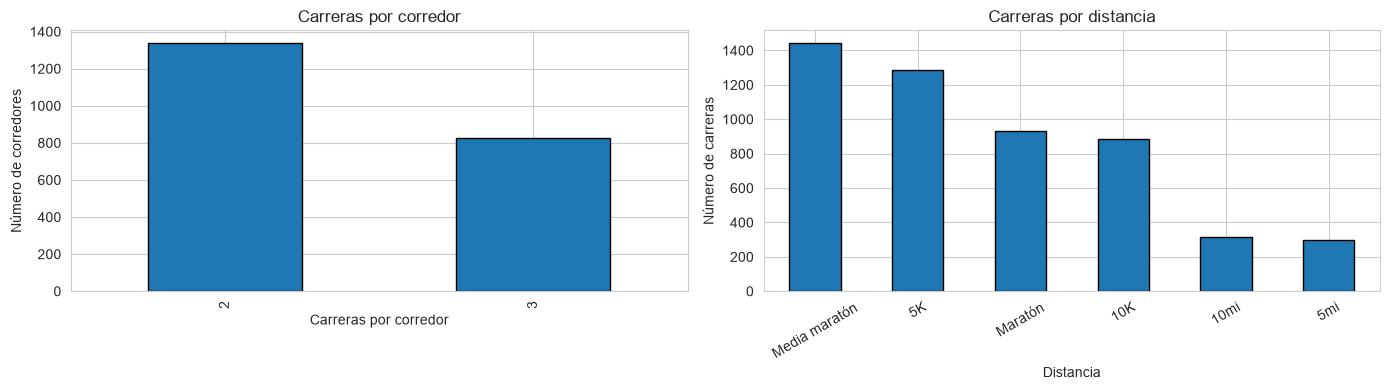

In [3]:
# @title Volumen y estructura
n_carreras = len(df_long)
n_corredores = df_long["id"].nunique()
carreras_por_corredor = df_long.groupby("id").size()

print(f"Carreras (ejemplos): {n_carreras}")
print(f"Corredores únicos:   {n_corredores}")
print(f"Carreras/corredor:   media={carreras_por_corredor.mean():.2f}, "
      f"min={carreras_por_corredor.min()}, max={carreras_por_corredor.max()}")

print("\n--- Carreras por distancia ---")
print(df_long["distancia"].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

carreras_por_corredor.value_counts().sort_index().plot(
    kind="bar", ax=axes[0], edgecolor="black"
)
axes[0].set_xlabel("Carreras por corredor")
axes[0].set_ylabel("Número de corredores")
axes[0].set_title("Carreras por corredor")

df_long["distancia"].value_counts().plot(kind="bar", ax=axes[1], edgecolor="black")
axes[1].set_xlabel("Distancia")
axes[1].set_ylabel("Número de carreras")
axes[1].set_title("Carreras por distancia")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 2.2. Distribución del objetivo (`velocity_kmh`)

--- Estadísticos de velocity_kmh ---
Media:     12.478
Mediana:   12.287
Desv. std: 2.595
Mínimo:    5.081
Máximo:    22.126
Asimetría: 0.315
Curtosis:  -0.113


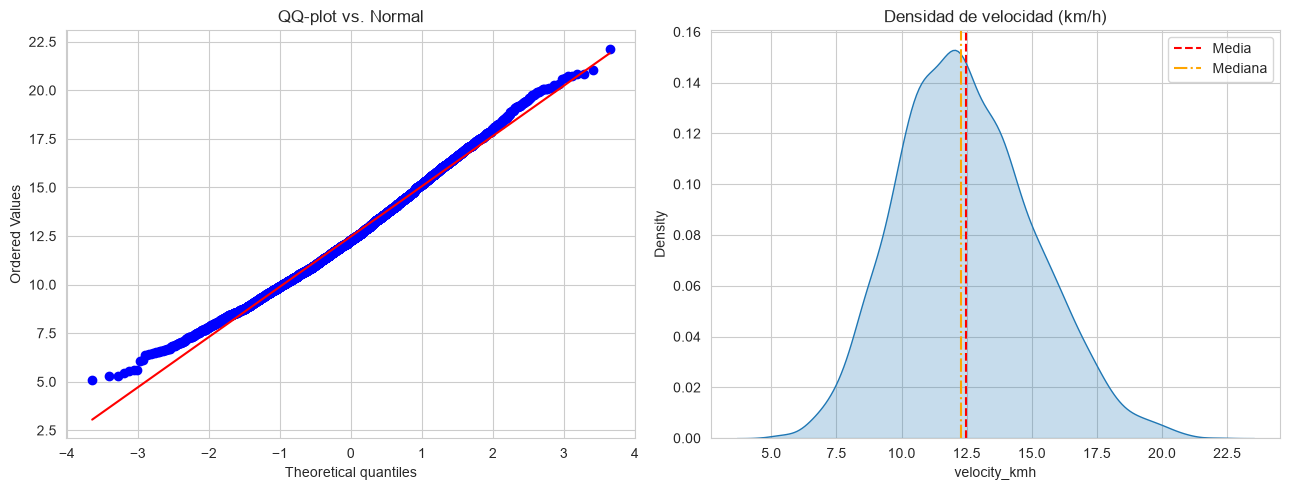

In [4]:
# @title Estadísticos y distribución de la velocidad
target = df_long["velocity_kmh"].dropna()

print("--- Estadísticos de velocity_kmh ---")
print(f"Media:     {target.mean():.3f}")
print(f"Mediana:   {target.median():.3f}")
print(f"Desv. std: {target.std():.3f}")
print(f"Mínimo:    {target.min():.3f}")
print(f"Máximo:    {target.max():.3f}")
print(f"Asimetría: {target.skew():.3f}")
print(f"Curtosis:  {target.kurtosis():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

stats.probplot(target, dist="norm", plot=axes[0])
axes[0].set_title("QQ-plot vs. Normal")

sns.kdeplot(target, ax=axes[1], fill=True)
axes[1].axvline(target.mean(), color="red", ls="--", label="Media")
axes[1].axvline(target.median(), color="orange", ls="-.", label="Mediana")
axes[1].set_title("Densidad de velocidad (km/h)")
axes[1].legend()

plt.tight_layout()
plt.show()

## 2.3. Distribución de variables de entrada

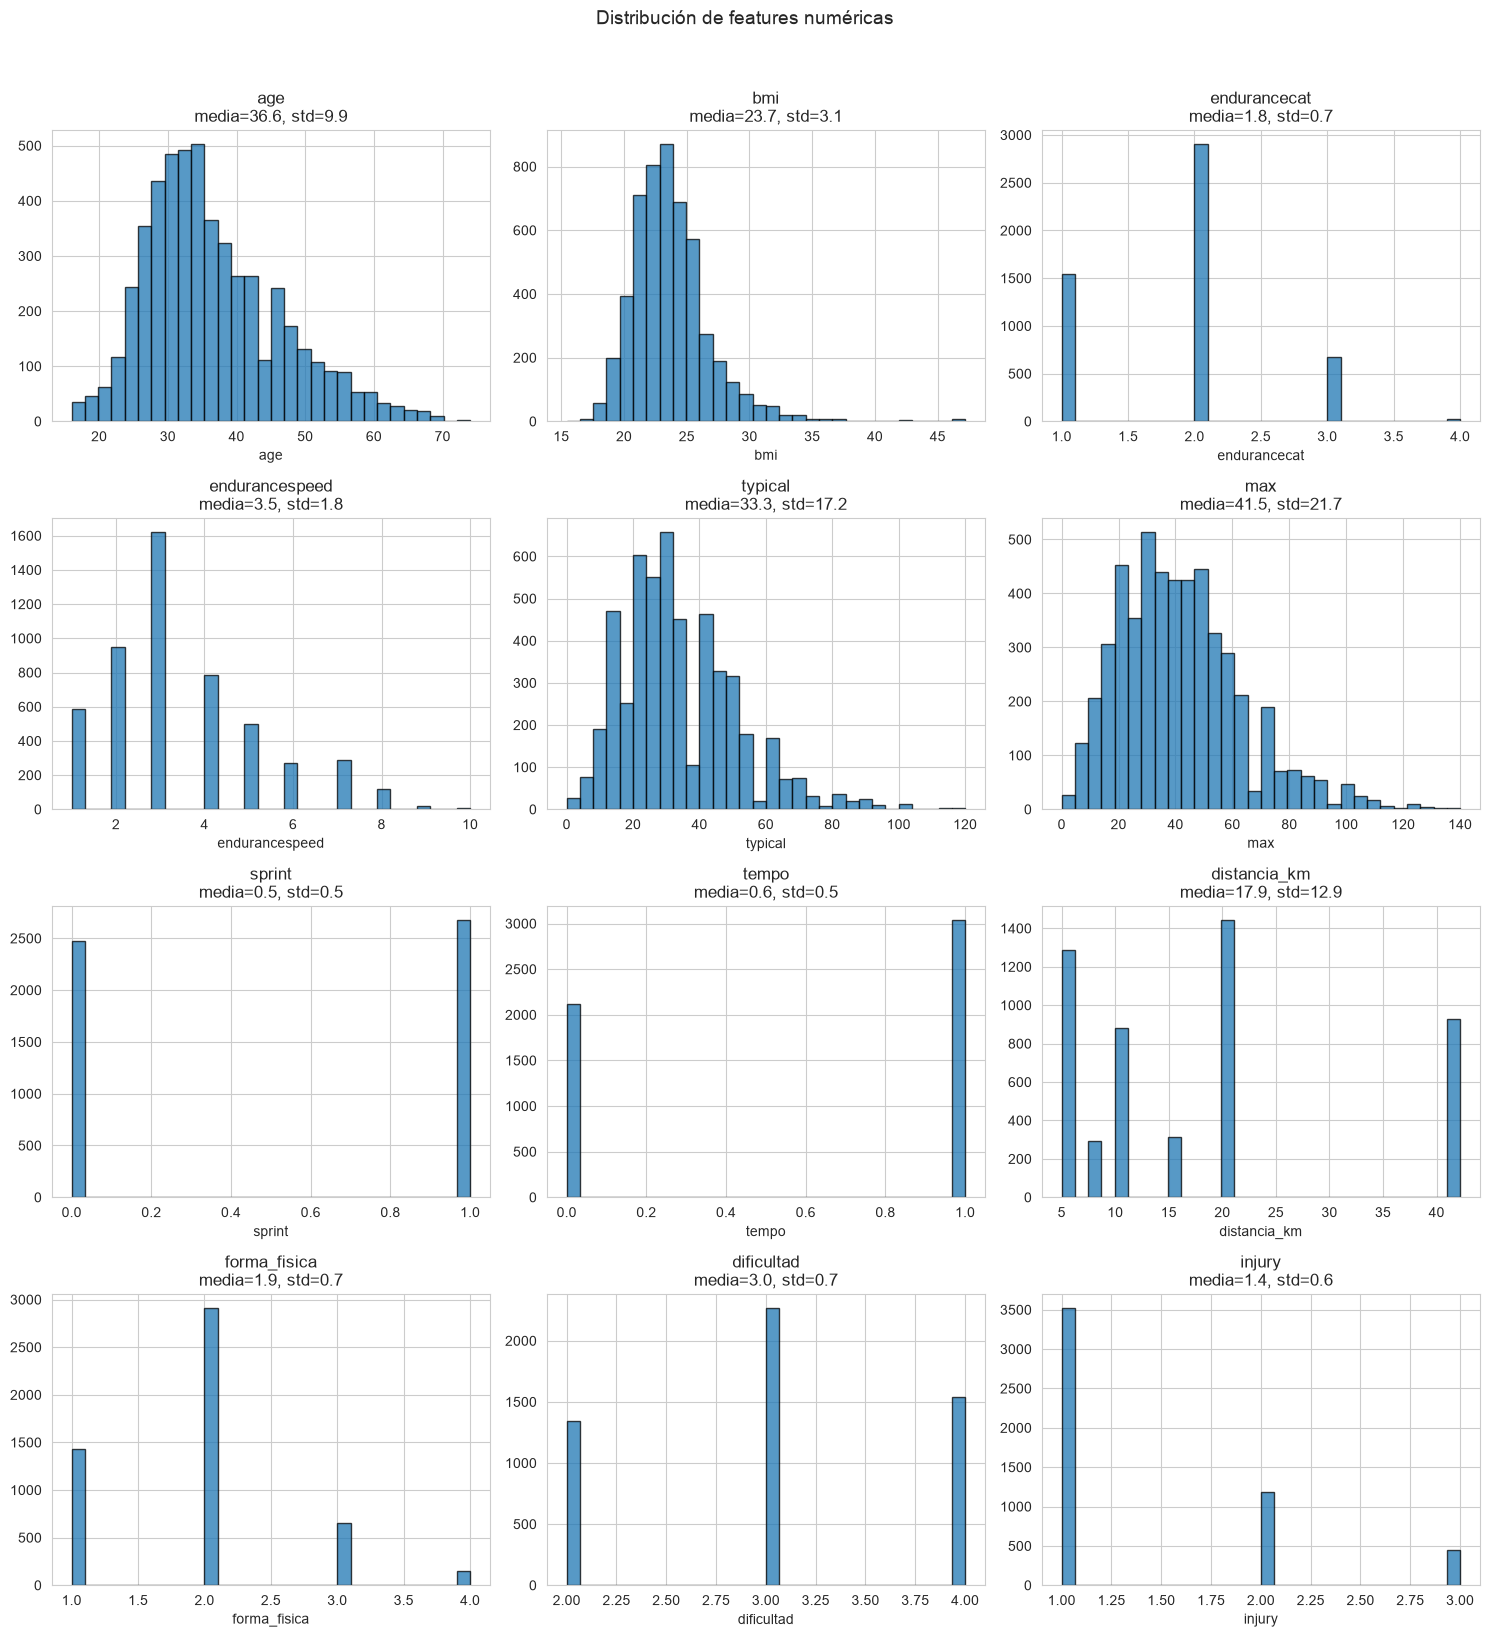

In [5]:
# @title Features numéricas: histogramas y correlación con el objetivo
numeric_features = [
    "age", "bmi", "endurancecat", "endurancespeed",
    "typical", "max", "sprint", "tempo", "distancia_km",
    "forma_fisica", "dificultad", "injury",
]
numeric_features = [c for c in numeric_features if c in df_long.columns]

n_cols = 3
n_rows = (len(numeric_features) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = np.array(axes).flatten()

for i, col in enumerate(numeric_features):
    axes[i].hist(df_long[col].dropna(), bins=30, edgecolor="black", alpha=0.75)
    axes[i].set_title(f"{col}\nmedia={df_long[col].mean():.1f}, std={df_long[col].std():.1f}")
    axes[i].set_xlabel(col)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Distribución de features numéricas", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

--- Correlación con velocity_kmh ---
velocity_kmh      1.000
typical           0.586
max               0.554
tempo             0.369
sprint            0.329
endurancespeed    0.220
endurancecat      0.195
dificultad        0.091
injury           -0.070
age              -0.169
forma_fisica     -0.206
distancia_km     -0.221
bmi              -0.367
Name: velocity_kmh, dtype: float64


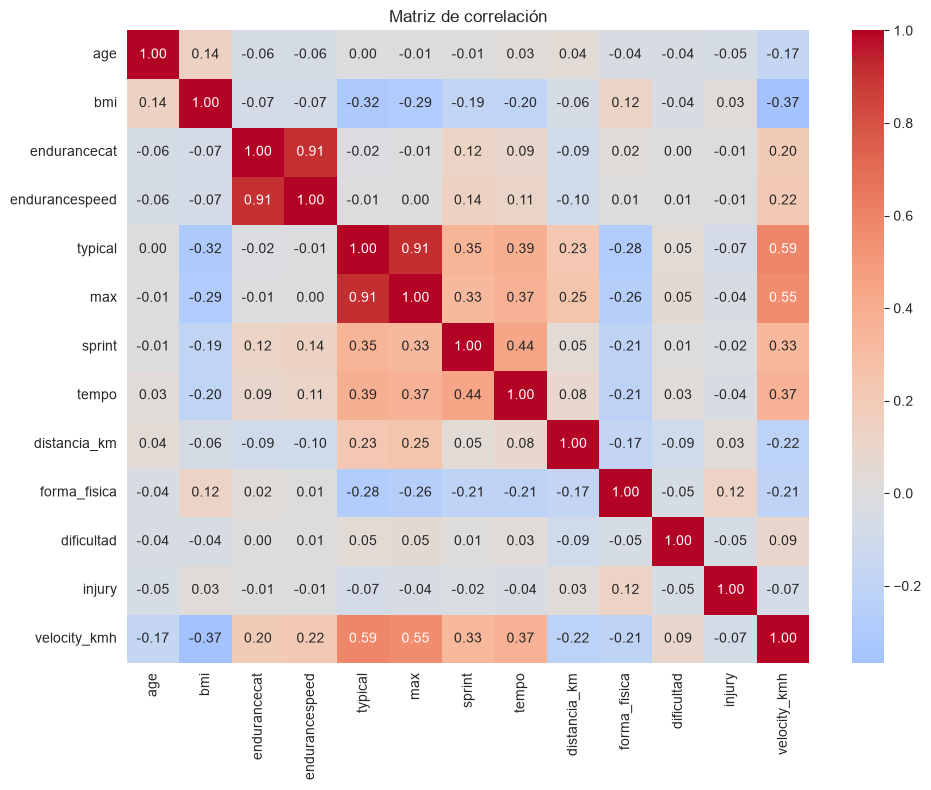

In [6]:
# @title Matriz de correlación con el objetivo
corr = df_long[numeric_features + ["velocity_kmh"]].corr()
corr_target = corr["velocity_kmh"].sort_values(ascending=False)

print("--- Correlación con velocity_kmh ---")
print(corr_target.round(3))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Matriz de correlación")
plt.tight_layout()
plt.show()

## 2.4. Datos faltantes y valores atípicos

In [8]:
# @title Faltantes
missing = df_long.isnull().sum()
missing_pct = (missing / len(df_long) * 100).round(2)

missing_df = pd.DataFrame({"Faltantes": missing, "Porcentaje": missing_pct}).sort_values(
    "Porcentaje", ascending=False
)
missing_df = missing_df[missing_df["Faltantes"] > 0]

if missing_df.empty:
    print("No hay valores faltantes en el dataset procesado.")
else:
    display(missing_df)

No hay valores faltantes en el dataset procesado.


In [9]:
# @title Outliers por IQR
def outliers_iqr(series: pd.Series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (series < lower) | (series > upper)
    return mask.sum(), lower, upper

rows = []
for col in numeric_features + ["velocity_kmh"]:
    s = df_long[col].dropna()
    n_out, lo, hi = outliers_iqr(s)
    rows.append({
        "Variable": col,
        "N atípicos": n_out,
        "% atípicos": f"{n_out / len(s) * 100:.2f}%",
        "Límite inf.": f"{lo:.2f}",
        "Límite sup.": f"{hi:.2f}",
    })

display(pd.DataFrame(rows))

,Variable,N atípicos,% atípicos,Límite inf.,Límite sup.
0,age,49,0.95%,8.00,64.00
1,bmi,161,3.12%,16.42,30.48
2,endurancecat,28,0.54%,-0.50,3.50
3,endurancespeed,146,2.83%,-1.00,7.00
4,typical,71,1.38%,-17.50,82.50
5,max,74,1.44%,-20.00,100.00
6,sprint,0,0.00%,-1.50,2.50
7,tempo,0,0.00%,-1.50,2.50
8,distancia_km,0,0.00%,-19.15,45.24
9,forma_fisica,152,2.95%,-0.50,3.50


## 2.5. Riesgos observados

**Fuga de información por corredor.** Cada corredor aporta entre 2 y 3 carreras. Una partición aleatoria pondría carreras del mismo corredor en `train` y `validación`, permitiendo al modelo memorizar características individuales. Esto inflaría artificialmente las métricas.

**Mitigación:** usar `GroupShuffleSplit` agrupando por `id` de corredor. Verificado explícitamente en la sección 3.

**Datos autorreportados.** La encuesta pudo introducir ruido en tiempos, kilometrajes y BMI. Los outliers se tratan como observaciones legítimas del fenómeno, no como errores.

<a name="3"></a>
# 3. Baselines

Antes de aplicar Deep Learning definimos dos puntos de comparación:

- **Media de velocidad por sexo:** predicción ingenua.
- **Ridge (regresión lineal regularizada L2):** mide cuánta señal es capturable linealmente.

Ambos se evalúan con la **misma partición por corredor**, el **mismo preprocesamiento** y las **mismas métricas** (MAE y RMSE) que la MLP.

In [10]:
# @title Features y utilidades
TARGET = "velocity_kmh"

FEATURE_GROUPS = {
    "demograficas":  ["age", "bmi", "female"],
    "entrenamiento": ["typical", "max", "sprint", "tempo", "endurancecat", "endurancespeed"],
    "carrera":       ["distancia_km", "forma_fisica", "dificultad"],
    "otras":         ["injury", "footwear"],
}
FEATURES = [c for cols in FEATURE_GROUPS.values() for c in cols]
print(f"{len(FEATURES)} features usadas:", FEATURES)

def split_by_runner(d: pd.DataFrame, val_size=0.15, test_size=0.15, seed=SEED):
    """Partición por corredor: ningún `id` aparece en más de un conjunto."""
    groups = d["id"].to_numpy()
    outer = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    trainval, test = next(outer.split(d, groups=groups))
    inner = GroupShuffleSplit(n_splits=1, test_size=val_size / (1 - test_size), random_state=seed)
    tr, va = next(inner.split(d.iloc[trainval], groups=groups[trainval]))
    return trainval[tr], trainval[va], test

def evaluate(y_true, y_pred) -> dict:
    err = np.asarray(y_true) - np.asarray(y_pred)
    return {"MAE": float(np.abs(err).mean()), "RMSE": float(np.sqrt((err ** 2).mean()))}

14 features usadas: ['age', 'bmi', 'female', 'typical', 'max', 'sprint', 'tempo', 'endurancecat', 'endurancespeed', 'distancia_km', 'forma_fisica', 'dificultad', 'injury', 'footwear']


In [12]:
# @title Partición por corredor y verificación explícita
assert not df_long[FEATURES + [TARGET]].isnull().any().any(), "Hay nulos en las features"

train_idx, val_idx, test_idx = split_by_runner(df_long)
train, val, test = (df_long.iloc[i].copy() for i in (train_idx, val_idx, test_idx))

# Verificación de fuga de información
train_ids = set(train["id"])
val_ids   = set(val["id"])
test_ids  = set(test["id"])

assert train_ids.isdisjoint(val_ids), "¡Fuga! Hay corredores en train y val."
assert train_ids.isdisjoint(test_ids), "¡Fuga! Hay corredores en train y test."
assert val_ids.isdisjoint(test_ids), "¡Fuga! Hay corredores en val y test."

print("Sin fuga de información entre conjuntos (verificado por ID de corredor).")
print(f"\nCarreras:    train={len(train)}, val={len(val)}, test={len(test)}")
print(f"Corredores:  train={len(train_ids)}, val={len(val_ids)}, test={len(test_ids)}")

Sin fuga de información entre conjuntos (verificado por ID de corredor).

Carreras:    train=3597, val=778, test=778
Corredores:  train=1514, val=325, test=325


In [13]:
# @title Entrenar baselines: media por sexo y Ridge
scaler = StandardScaler().fit(train[FEATURES])
X_train = scaler.transform(train[FEATURES])
X_val   = scaler.transform(val[FEATURES])
y_train = train[TARGET].to_numpy()
y_val   = val[TARGET].to_numpy()

# Baseline 1: media de velocidad por sexo
mean_by_sex = train.groupby("female")[TARGET].mean()
pred_sex = val["female"].map(mean_by_sex).fillna(y_train.mean()).to_numpy()

# Baseline 2: Ridge
ridge = Ridge(alpha=1.0).fit(X_train, y_train)
pred_ridge = ridge.predict(X_val)

results = {
    "Media por sexo": evaluate(y_val, pred_sex),
    "Ridge":          evaluate(y_val, pred_ridge),
}
display(pd.DataFrame(results).T.round(3).rename_axis("Modelo (validación)"))

,MAE,RMSE
Modelo (validación),,
Media por sexo,1.988,2.441
Ridge,1.140,1.454


In [14]:
# @title Coeficientes estandarizados de Ridge
coefs = pd.Series(ridge.coef_, index=FEATURES).sort_values(key=np.abs, ascending=False)
print("Coeficientes de Ridge (km/h por 1 desv. est. de la feature)")
print(coefs.round(3))

Coeficientes de Ridge (km/h por 1 desv. est. de la feature)
female           -0.941
typical           0.933
distancia_km     -0.894
bmi              -0.595
age              -0.476
endurancespeed    0.292
max               0.237
tempo             0.222
forma_fisica     -0.204
sprint            0.103
endurancecat     -0.069
footwear         -0.064
injury           -0.005
dificultad        0.005
dtype: float64


**Lectura rápida:** las variables de entrenamiento (`typical`, `max`, `tempo`, `sprint`) dominan la predicción. `female`, `distancia_km`, `bmi` y `age` también aportan, con signo negativo coherente con la literatura. `injury` y `dificultad` contribuyen poco.

<a name="4"></a>
# 4. Familia de modelos: MLP

Se propone una **MLP pequeña** en PyTorch porque las entradas son tabulares (numéricas y categóricas codificadas) y el objetivo es capturar interacciones no lineales entre volumen de entrenamiento, intensidad y demografía.

**Arquitectura:** 2 capas ocultas (64, 32), ReLU, Dropout(0.2), Weight Decay(L2) en el optimizador.

In [16]:
# @title Definición de la MLP y utilidades de entrenamiento
class MLP(nn.Module):
    """MLP para regresión tabular.

    entrada (n_features) → Linear(64)+ReLU+Dropout → Linear(32)+ReLU+Dropout → Linear(1)
    """
    def __init__(self, n_features, hidden=(64, 32), dropout=0.2):
        super().__init__()
        layers, prev = [], n_features
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def make_loader(X, y, batch_size=64, shuffle=True, seed=SEED):
    ds = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32),
    )
    g = torch.Generator().manual_seed(seed)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=g)


def predict(model, loader):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(xb.to(DEVICE)).cpu() for xb, _ in loader]).numpy()


def train_mlp(X_train, y_train, X_val, y_val,
              epochs=80, lr=1e-3, weight_decay=1e-4, seed=SEED):
    torch.manual_seed(seed)
    model = MLP(X_train.shape[1]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.MSELoss()

    train_loader      = make_loader(X_train, y_train, shuffle=True, seed=seed)
    train_eval_loader = make_loader(X_train, y_train, shuffle=False)
    val_loader        = make_loader(X_val, y_val, shuffle=False)

    hist = {"train": [], "val": []}
    for _ in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            opt.step()

        yp_tr = predict(model, train_eval_loader)
        yp_va = predict(model, val_loader)
        hist["train"].append(float(np.sqrt(((yp_tr - y_train) ** 2).mean())))
        hist["val"].append(float(np.sqrt(((yp_va - y_val) ** 2).mean())))
    return model, hist

<a name="5"></a>
# 5. Primer experimento: Ridge vs. MLP

**Hipótesis:** una MLP pequeña captura interacciones no lineales entre variables de entrenamiento y demográficas que Ridge no, reduciendo el RMSE de validación.

**Diseño:**
- Mismas features, misma partición por corredor, mismo preprocesamiento.
- **Sin ajuste de hiperparámetros** en esta fase.
- Métrica principal: **RMSE** (MAE como secundaria).

**Interpretación esperada:**
- Si RMSE(MLP) < RMSE(Ridge) → la hipótesis se apoya.
- Si RMSE(MLP) ≥ RMSE(Ridge) → la relación es esencialmente lineal con estas features; la MLP no aporta y esto también es un hallazgo válido, no un fracaso.

In [17]:
# @title Entrenar MLP y comparar con Ridge
mlp, hist = train_mlp(X_train, y_train, X_val, y_val)

mlp.eval()
with torch.no_grad():
    pred_mlp = mlp(torch.tensor(X_val, dtype=torch.float32).to(DEVICE)).cpu().numpy()

results["MLP"] = evaluate(y_val, pred_mlp)
display(pd.DataFrame(results).T.round(3).rename_axis("Modelo (validación)"))

,MAE,RMSE
Modelo (validación),,
Media por sexo,1.988,2.441
Ridge,1.140,1.454
MLP,1.166,1.503


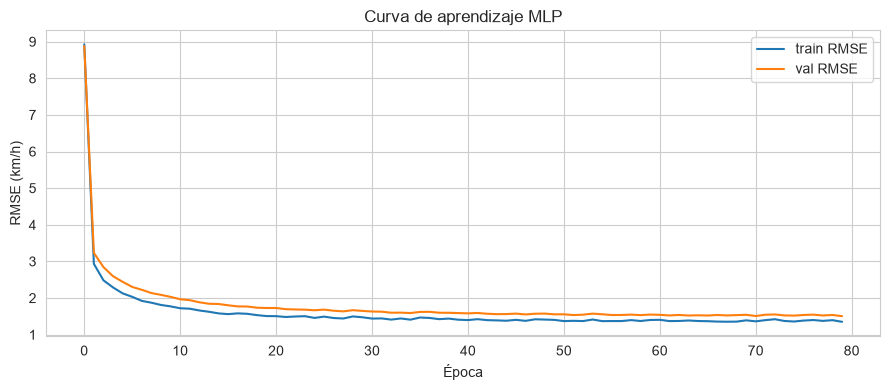

In [18]:
# @title Curva de aprendizaje
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hist["train"], label="train RMSE")
ax.plot(hist["val"],   label="val RMSE")
ax.set_xlabel("Época")
ax.set_ylabel("RMSE (km/h)")
ax.set_title("Curva de aprendizaje MLP")
ax.legend()
plt.tight_layout()
plt.show()

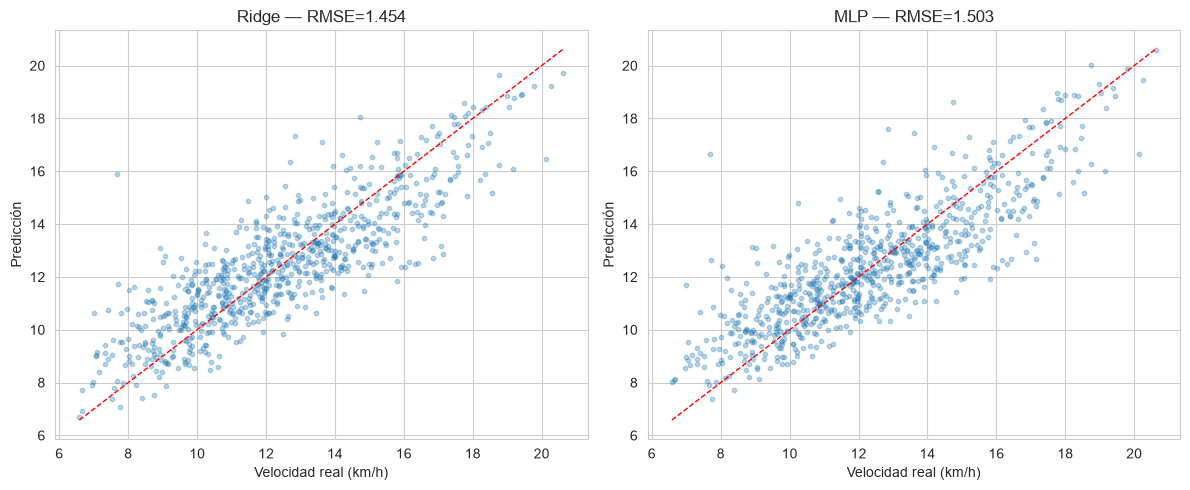

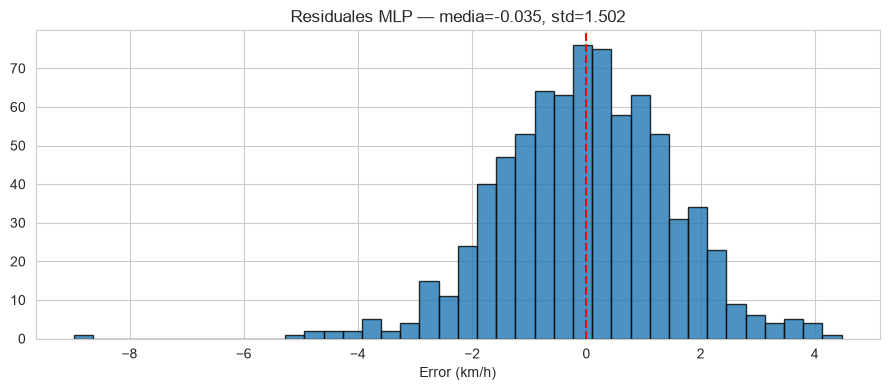

In [19]:
# @title Diagnóstico: predicciones vs. real y residuales
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, pred) in zip(axes, [("Ridge", pred_ridge), ("MLP", pred_mlp)]):
    ax.scatter(y_val, pred, alpha=0.3, s=10)
    lims = [min(y_val.min(), pred.min()), max(y_val.max(), pred.max())]
    ax.plot(lims, lims, "r--", lw=1)
    ax.set_xlabel("Velocidad real (km/h)")
    ax.set_ylabel("Predicción")
    ax.set_title(f"{name} — RMSE={results[name]['RMSE']:.3f}")
plt.tight_layout()
plt.show()

residuals = y_val - pred_mlp
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(residuals, bins=40, edgecolor="black", alpha=0.8)
ax.axvline(0, color="red", ls="--")
ax.set_title(f"Residuales MLP — media={residuals.mean():.3f}, std={residuals.std():.3f}")
ax.set_xlabel("Error (km/h)")
plt.tight_layout()
plt.show()

<a name="6"></a>
# 6. Conclusiones preliminares

**Sobre la pregunta de investigación.** Este notebook **no** la responde todavía. Aquí solo verificamos que el pipeline es viable y damos un orden de magnitud del error.

**Lo que sí observamos:**

1. **El pipeline funciona de punta a punta** con partición por corredor, preprocesamiento consistente y evaluación con MAE/RMSE. Esto era el objetivo principal de la primera entrega.
2. **Ridge obtiene menor RMSE que la MLP en esta prueba preliminar.** Este resultado es válido y orienta el análisis: con las features actuales, la relación entre entradas y velocidad parece predominantemente lineal.
3. **Las variables de entrenamiento son las que más aportan** según los coeficientes de Ridge. La pregunta de cuánto aportan sobre las demográficas se responderá formalmente en `modelo/` mediante un ablation study.

**Siguientes pasos (entrega final, en `modelo/`):**

1. **Ablation study:** entrenar Ridge y MLP con y sin variables de entrenamiento, con la misma partición. Responder si la ganancia viene de las features o de la no linealidad.
2. **Block CV agrupada por corredor** con varias semillas para robustez.
3. **Gradient boosting** como referencia adicional para separar la ganancia por no linealidad de la específica de una red neuronal.
4. Si Ridge sigue igual o mejor que la MLP con todas las features, el proyecto se reorienta a un **diagnóstico de aporte de variables**, sin cambiar de familia de modelo.